In [2]:
import os, json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm
from src import Questions


plt.rcParams.update({'font.size': 14})

In [2]:
# creating a dataframe of all of the annotator profiles
EXCLUDED_SCORES = ["2_13", "23_", "24_", "25_", "27_"]
EXCLUDED_WHOLE = [23, 24, 25, 27]
questions = Questions().get_questions()
SCORED_ANNOTATOR_DIR = "annotation_artefacts/final_annotator_objects"
os.makedirs(SCORED_ANNOTATOR_DIR, exist_ok=True)


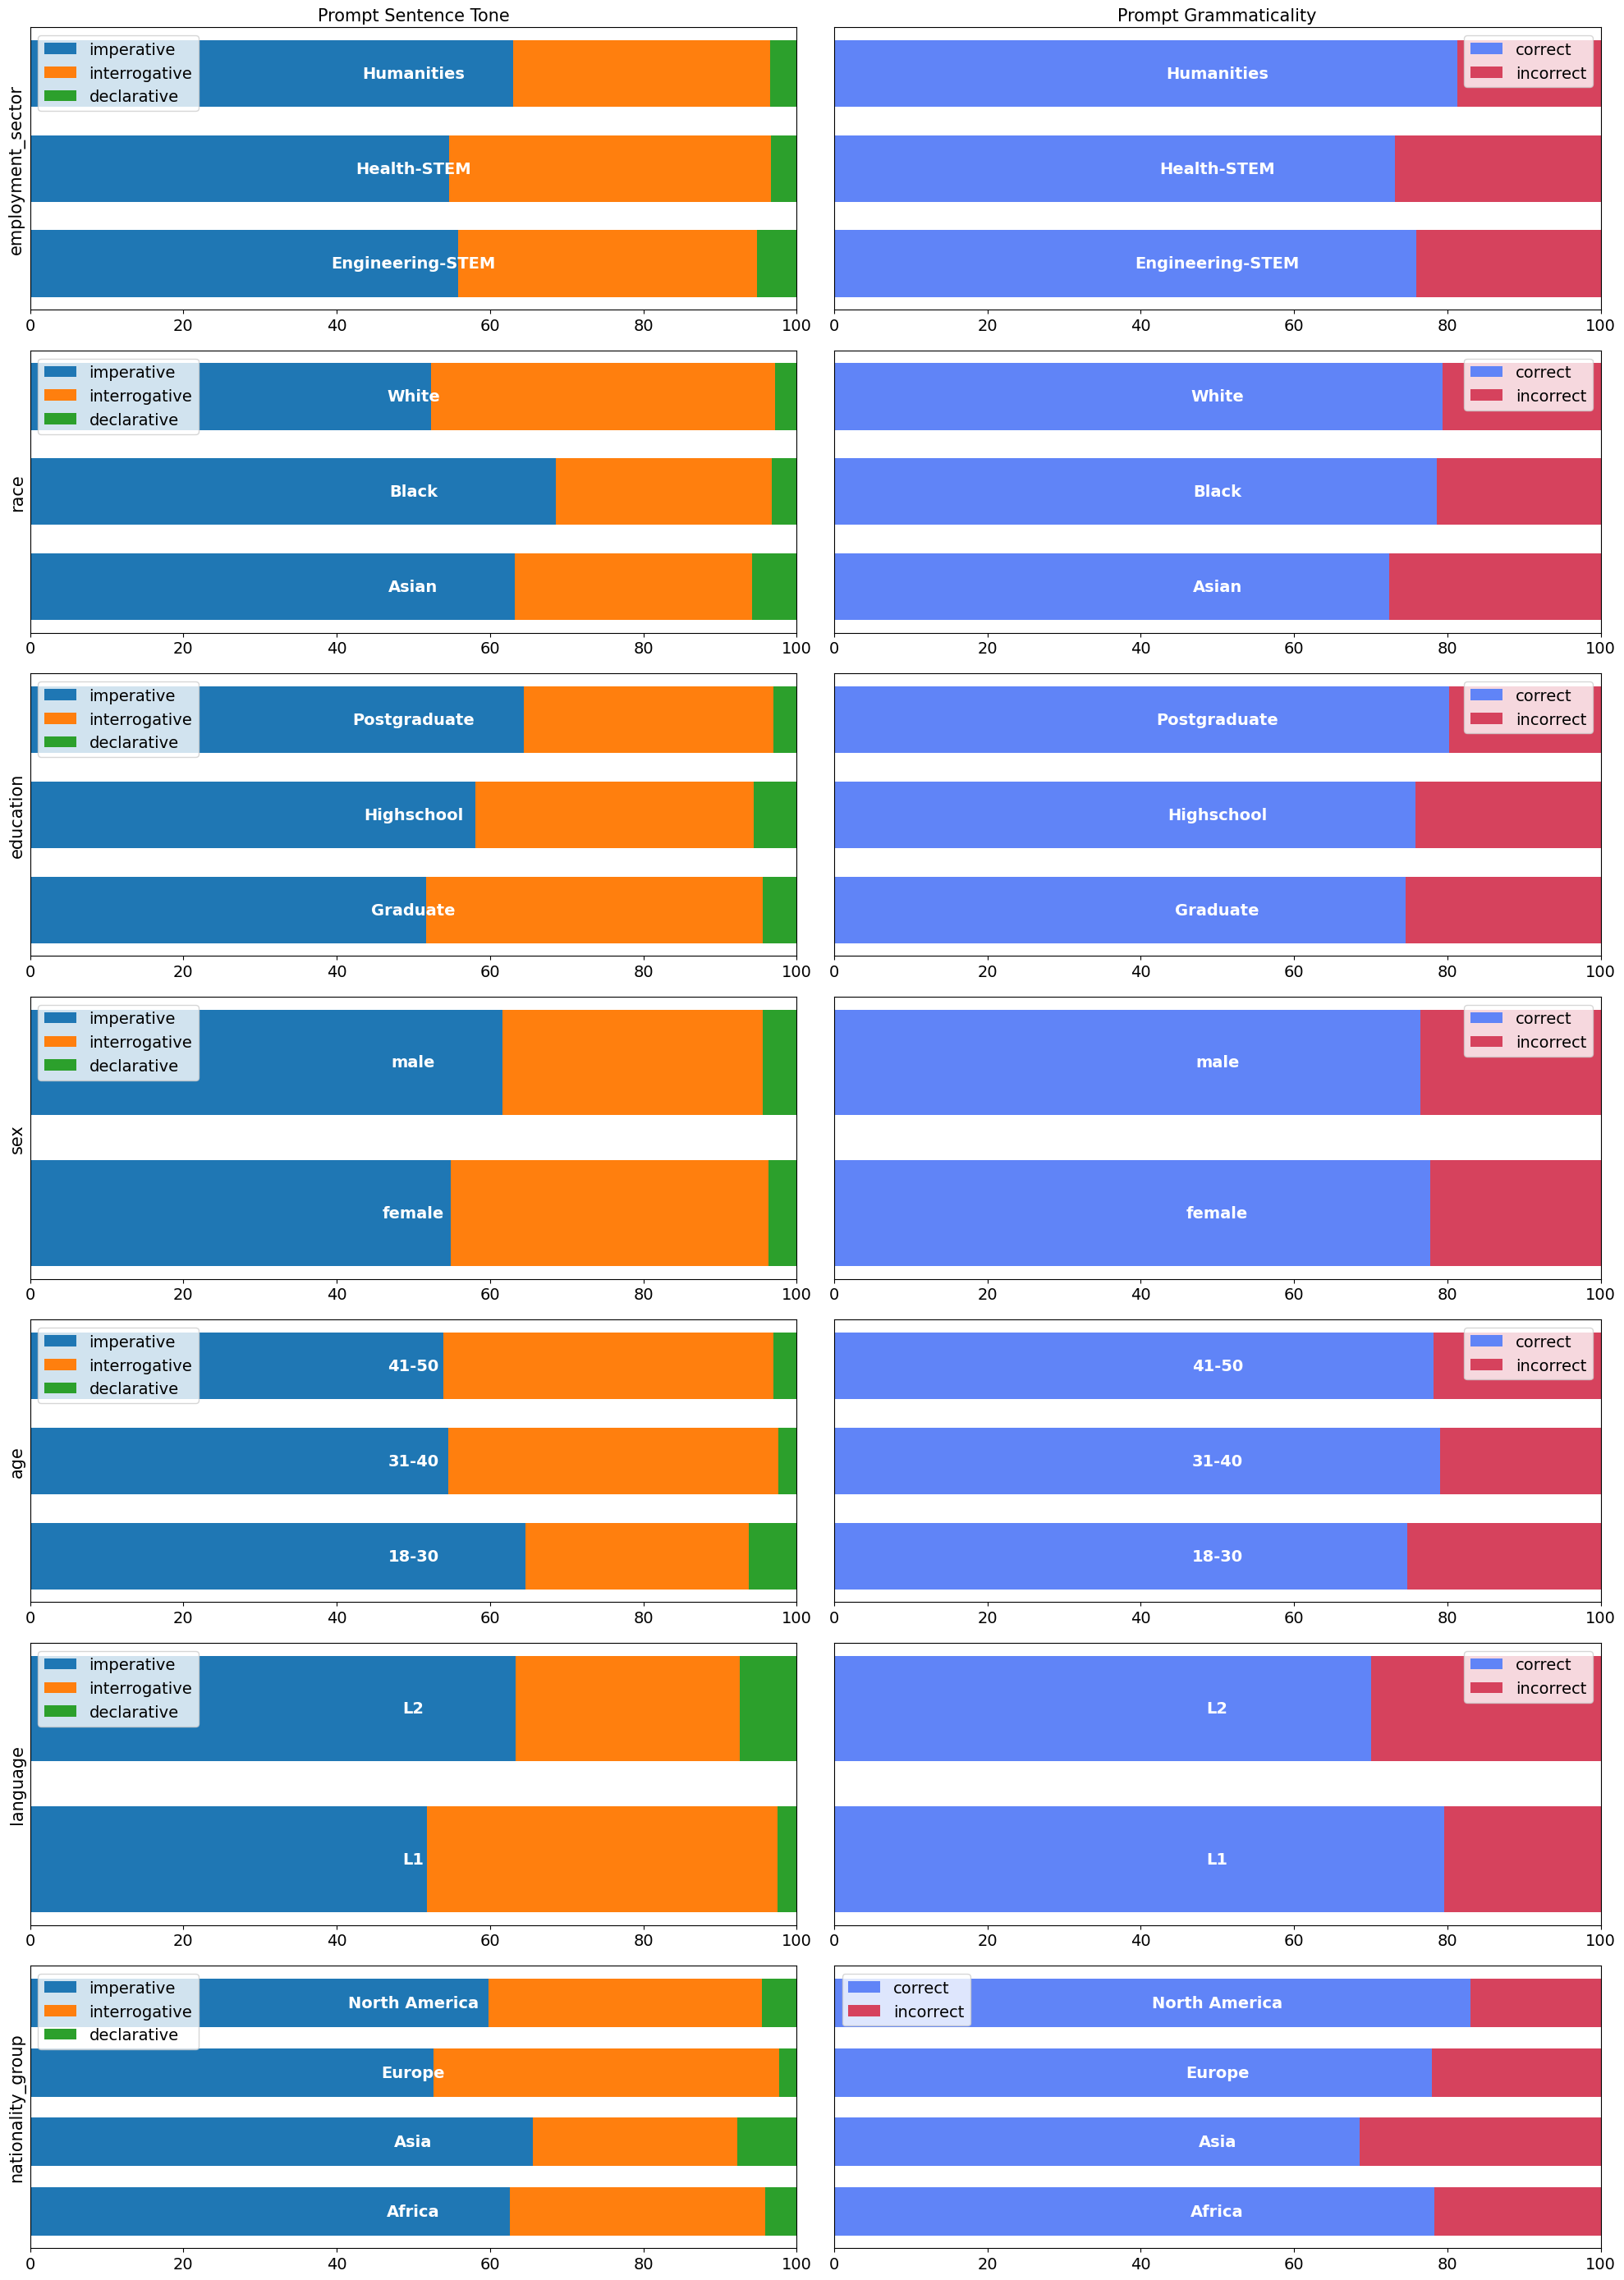

In [4]:
from src.utils.viz_utils import plot_histogram_by_category, plot_grouped_bar_chart, plot_stacked_bar_chart

# making a df that has info: sum sentence length, freq count for each of the annotators
df_ptype_freqtable = []
for annfilename in os.listdir(SCORED_ANNOTATOR_DIR):
    annotator_filepath = os.path.join(SCORED_ANNOTATOR_DIR, annfilename)
    with open(annotator_filepath, "r") as  ao:
        annotator_object = json.load(ao)
    
    prompt_lengths = []
    prompt_tone_freq_table = {
        "imperative" : 0,
        "interrogative" : 0,
        "declarative" : 0,
    }
    prompt_grammar_freq_table = {
        "correct" : 0,
        "incorrect" : 0,
    }
    
    for i, (question, v) in enumerate(annotator_object["answers"].items()):
        if i not in EXCLUDED_WHOLE :
            if v["answer"]:
                prompt_lengths.append(v["sentence_length"])
                prompt_tone_freq_table[v["sentence_type"]] += 1
                prompt_grammar_freq_table[v["grammaticality"]] += 1

    df_ptype_freqtable.append({
        "id" : annotator_object["id"],
        **annotator_object["profile"],
        "sum_prompt_lengths" : sum(prompt_lengths),
        **prompt_tone_freq_table,
        **prompt_grammar_freq_table
    })

df_ptype_freqtable = sorted(df_ptype_freqtable, key=lambda x: x["id"])
df_ptype_freqtable = pd.DataFrame(df_ptype_freqtable)


aggregates = {}
PROFILE_COLUMNS = ["employment_sector", "race", "education", "sex", "age", "language", "nationality_group"]
for pc in PROFILE_COLUMNS:
    aggregates[pc] = {}
    for demo_label_name, group_df in df_ptype_freqtable.groupby(pc):
        # implementing exceptions
        if pc == "employment_sector":
            group = group_df[group_df["language"] == "L1"]
        elif pc == "education":
            group = group_df[group_df["language"] == "L1"]
        elif pc == "sex":
            group = group_df[group_df["language"] == "L1"]
            
        elif(demo_label_name == "Black"):
            group = group_df[group_df["language"] == "L1"]
        elif(demo_label_name == "White"):
            group = group_df[group_df["language"] == "L1"]
        # implementing exceptions
        demo_label_plengths = group_df["sum_prompt_lengths"].to_list()
        
        tone_ftable = group_df[['imperative', 'interrogative', 'declarative']]
        tone_sums = tone_ftable.sum().to_dict()

        grammar_ftable = group_df[['correct', 'incorrect']]
        grammar_sums = grammar_ftable.sum().to_dict()

        group_stats = {
            "Prompt Lengths" : demo_label_plengths,
            "Prompt Tone" : tone_sums,
            "Prompt Grammar" : grammar_sums,
        }

        aggregates[pc][demo_label_name] = group_stats
# # visualizing
N = len(PROFILE_COLUMNS)
fig, axes = plt.subplots(N, 2, figsize=(20, 4 * N))

LABELSIZE=15

# Column labels
# column_labels = ['Sentence Length Histogram', 'Prompt Sentence Tone', 'Prompt Grammaticality']
column_labels = ['Prompt Sentence Tone', 'Prompt Grammaticality']
for col, label in enumerate(column_labels):
    axes[0, col].set_title(label, fontsize=LABELSIZE)

# Row labels
for row, label in enumerate(PROFILE_COLUMNS):
    axes[row, 0].set_ylabel(label, fontsize=LABELSIZE, rotation=90)

nrows, ncols = axes.shape
for i, j in np.ndindex(nrows, ncols):
    ax = axes[i, j]
    demo_profile = PROFILE_COLUMNS[i]
    demo_data = aggregates[demo_profile]
    # if j == 0:
    #     data = {k : v["Prompt Lengths"] for k, v in demo_data.items()}
    #     plot_histogram_by_category(data, ax)
    if j == 0:
        data = {k : v["Prompt Tone"] for k, v in demo_data.items()}
        plot_stacked_bar_chart(data, ax, height=0.7)
    else:
        data = {k : v["Prompt Grammar"] for k, v in demo_data.items()}
        plot_stacked_bar_chart(data, ax, height=0.7)

plt.tight_layout()
plt.show()

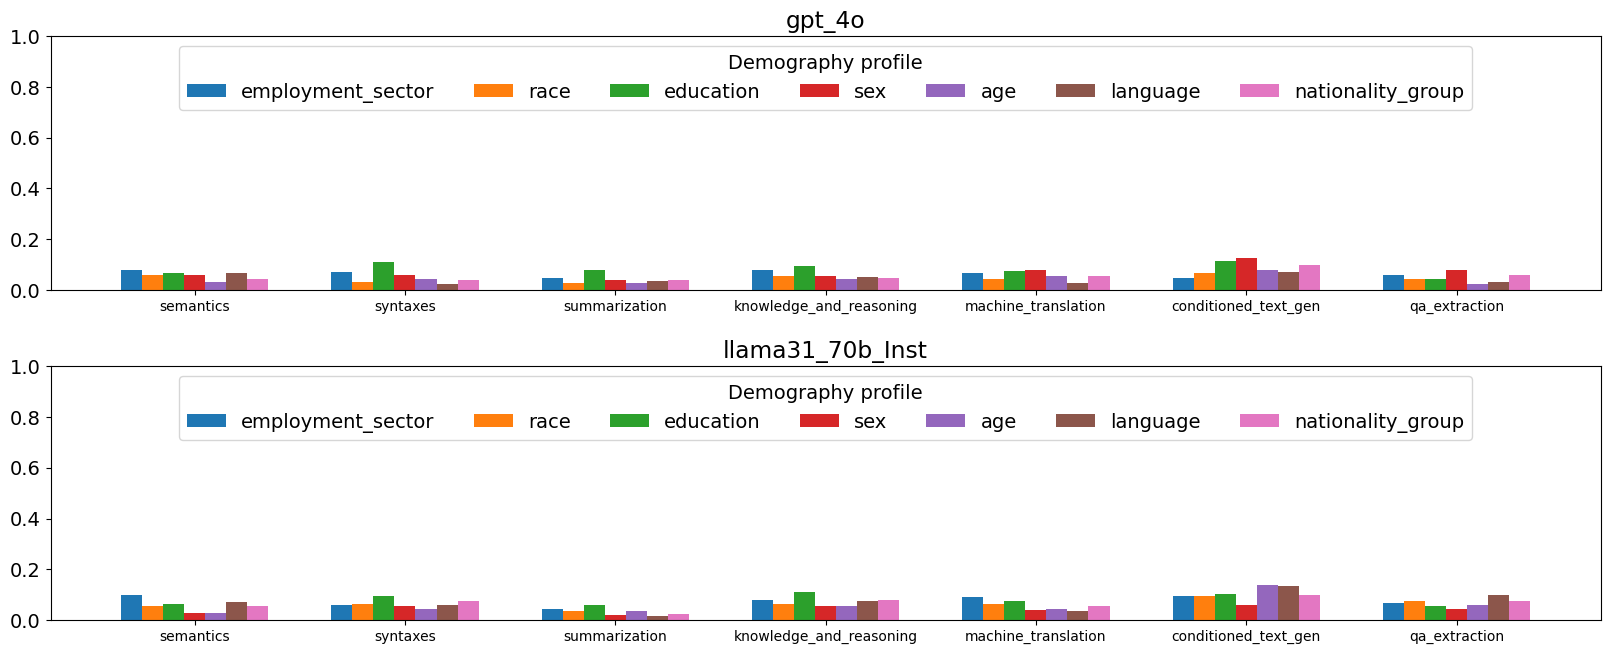

In [86]:
divscores_path="score_tables/divscores"
gap_score_result_files = os.listdir(divscores_path)

included_models = [
    "gpt_4o",
    "llama31_70b_Inst",
]

def transpose_dict(dict_input):
    swapped = {}
    for outer_key, inner_dict in dict_input.items():
        for inner_key, value in inner_dict.items():
            swapped.setdefault(inner_key, {})[outer_key] = value
    return swapped

data_full = {}
for model in included_models:
    data_full[model] = {}
    for tg_file in gap_score_result_files:
        if "model_v_taskg.csv" in tg_file:
            continue
        task_group = tg_file.replace("divscores_","").replace(".csv","")
        df_asjs = json.loads(pd.read_csv(f"{divscores_path}/{tg_file}", index_col=0).set_index('model').to_json(orient='index'))
        data_full[model][task_group] = df_asjs[model]

bar_width = 0.1
fig, axes = plt.subplots(len(data), 1, figsize=(20, 4 * len(data)))
for i, ax in enumerate(axes):
    model_data = transpose_dict(data_full[included_models[i]])
    for j, (demo_profile, topics) in enumerate(model_data.items()):
        x = np.arange(len(topics))
        ax.bar(x + j*bar_width, topics.values(), width=bar_width, label=demo_profile)      # <-- label only

    # print(list(topics.keys()))
    ax.set_xticks(x + bar_width*(len(model_data)-1)/2)
    ax.set_xticklabels(list(topics.keys()), fontsize=10)
    ax.legend(title="Demography profile", ncol=7, loc='upper center')
    ax.set_title(included_models[i])
    ax.set_ylim(0,1)
fig.subplots_adjust(hspace=0.3, bottom=0.15)
plt.show()

In [42]:
print(json.dumps(model_data, indent=4))

{
    "employment_sector": {
        "semantics": 0.0978516156,
        "syntaxes": 0.0608661899,
        "summarization": 0.0441746639,
        "knowledge_and_reasoning": 0.077730375,
        "machine_translation": 0.0908516682,
        "conditioned_text_gen": 0.0968329916,
        "qa_extraction": 0.0662305398
    },
    "race": {
        "semantics": 0.0559028238,
        "syntaxes": 0.0633275486,
        "summarization": 0.0346137128,
        "knowledge_and_reasoning": 0.0647509927,
        "machine_translation": 0.0640925038,
        "conditioned_text_gen": 0.0962090036,
        "qa_extraction": 0.0770540265
    },
    "education": {
        "semantics": 0.0649400742,
        "syntaxes": 0.0959512298,
        "summarization": 0.059119399,
        "knowledge_and_reasoning": 0.1111728574,
        "machine_translation": 0.0740624441,
        "conditioned_text_gen": 0.1013495277,
        "qa_extraction": 0.0539697436
    },
    "sex": {
        "semantics": 0.0282657204,
        "synt

In [43]:
print(json.dumps(data["llama31_70b_Inst"], indent=4))

{
    "semantics": {
        "employment_sector": 0.0978516156,
        "race": 0.0559028238,
        "education": 0.0649400742,
        "sex": 0.0282657204,
        "age": 0.029821332,
        "language": 0.0723368195,
        "nationality_group": 0.0548091469
    },
    "syntaxes": {
        "employment_sector": 0.0608661899,
        "race": 0.0633275486,
        "education": 0.0959512298,
        "sex": 0.0547296825,
        "age": 0.0422098227,
        "language": 0.0610838636,
        "nationality_group": 0.0758586241
    },
    "summarization": {
        "employment_sector": 0.0441746639,
        "race": 0.0346137128,
        "education": 0.059119399,
        "sex": 0.0186736234,
        "age": 0.0340820254,
        "language": 0.0174772118,
        "nationality_group": 0.0249348402
    },
    "knowledge_and_reasoning": {
        "employment_sector": 0.077730375,
        "race": 0.0647509927,
        "education": 0.1111728574,
        "sex": 0.0557778884,
        "age": 0.0571780

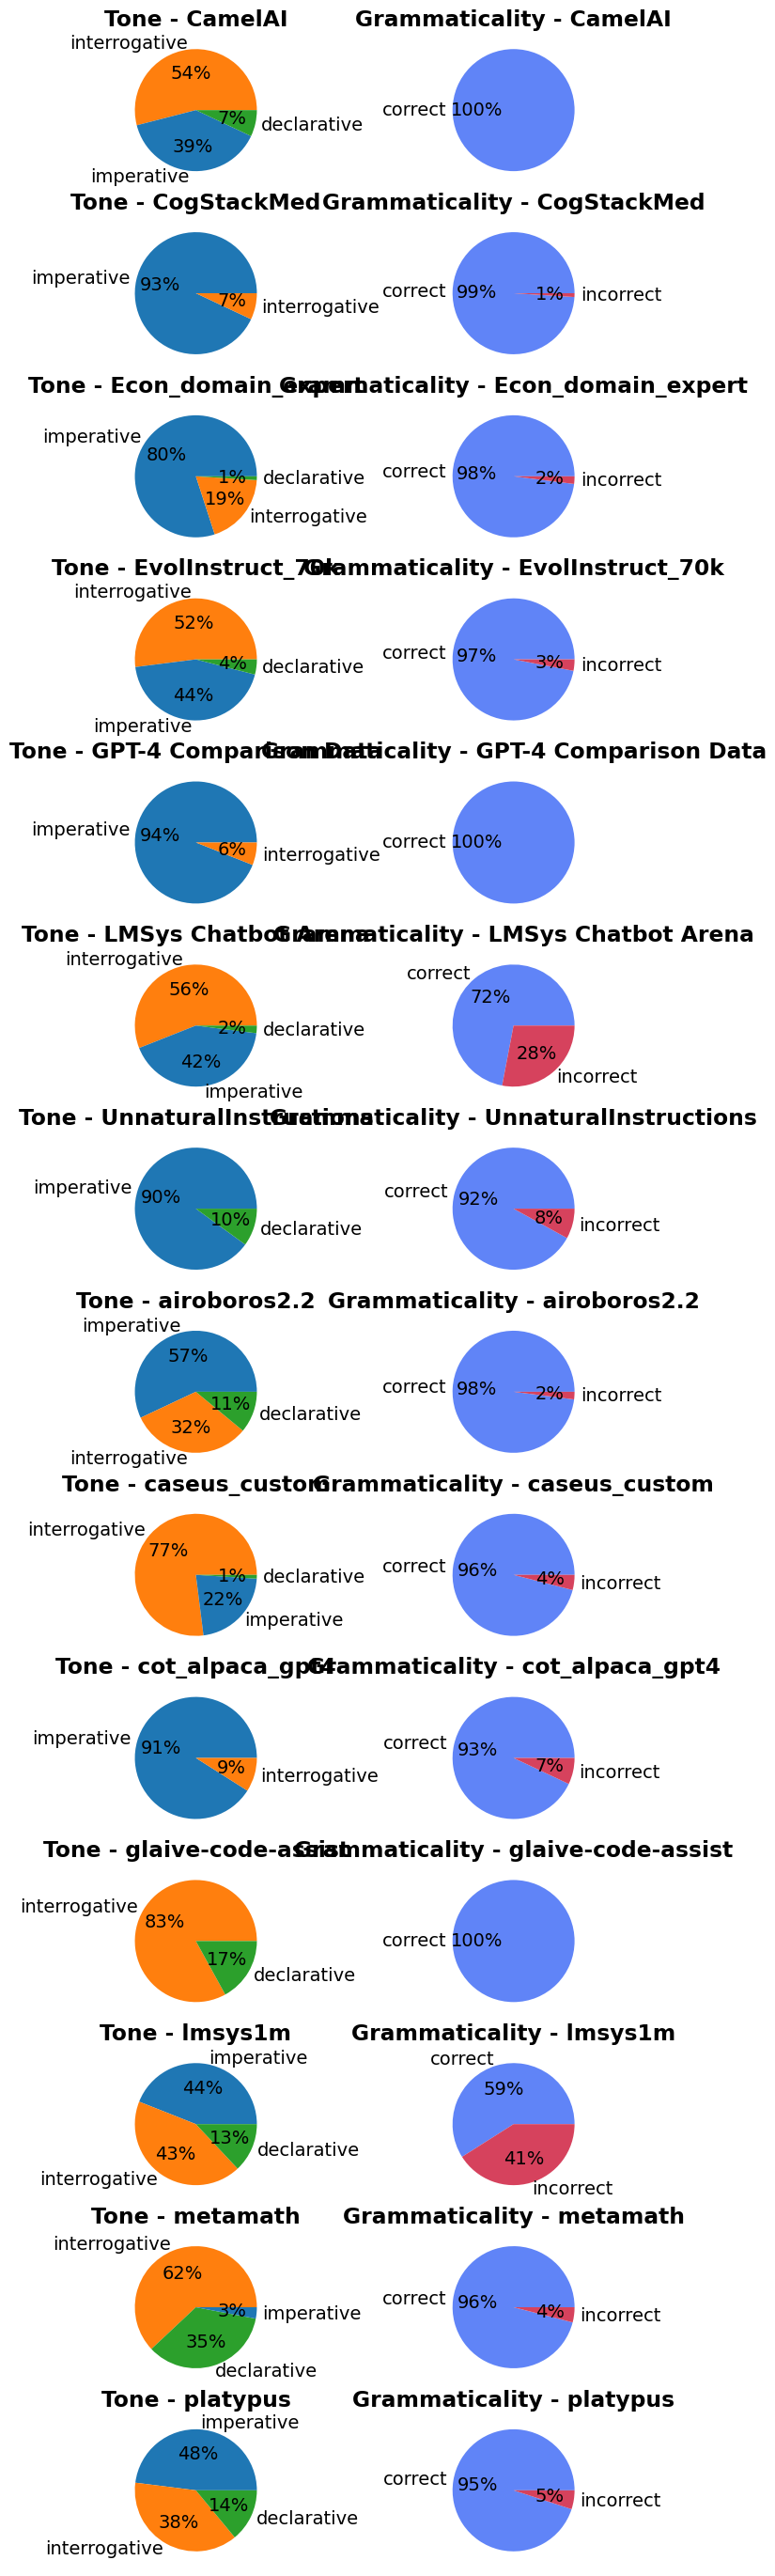

In [3]:
import json
import pandas as pd

INST_TUNING_CLASSIF_DS = "inst_tuning_analysis/openhermes2_5_sample.csv"
INST_TUNING_CLASSIF_HISTORY = "inst_tuning_analysis/inst_tuning_analysis/history-inst_tuning_analysis.json"
history_file = json.load(open(INST_TUNING_CLASSIF_HISTORY, "r"))

public_inst_df = pd.read_csv(INST_TUNING_CLASSIF_DS)[["source", "instruction"]]

tone_answers = []
for msg in history_file['tone_classification-chatgpt_4o_latest']['messages']:
    answer = msg['chat_history'][1]["content"].lower()
    tone_answers.append(answer)


grammar_answer = []
for msg in history_file['grammar_classification-chatgpt_4o_latest']['messages']:
    answer = msg['chat_history'][1]["content"].lower()
    grammar_answer.append(answer)

public_inst_df['tone'] = tone_answers
public_inst_df['grammaticality'] = grammar_answer

full_data = {}
for groupname, group in public_inst_df.groupby("source"):
    full_data[groupname] = {
        "tone" : group['tone'].value_counts().to_dict(),
        "grammaticality" : group['grammaticality'].value_counts().to_dict(),
    }


color_dict = {
    "imperative" : "#1f77b4",
    "interrogative" : "#ff7f0e",
    "declarative" : "#2ca02c",
    "correct" : "#6084f7",
    "incorrect" : "#d6425d",
}

#  Sort keys to make consistent grid layout
keys = sorted(full_data.keys())
n = len(keys)

fig, axes = plt.subplots(nrows=n, ncols=2, figsize=(8, n * 2.5))

for i, key in enumerate(keys):
    d = full_data[key]
    # Tones (left column)
    tone_ax = axes[i][0]
    tone_data = d['tone']
    tone_labels = list(tone_data.keys())
    tone_values = list(tone_data.values())
    tone_colors_used = [color_dict[label] for label in tone_labels]
    tone_ax.pie(tone_data.values(), labels=tone_data.keys(), autopct='%1.0f%%', colors=tone_colors_used)
    tone_ax.set_title(f'Tone - {key}', fontweight="bold")

    # Grammar (right column)
    grammar_ax = axes[i][1]
    grammar_data = d['grammaticality']
    grammar_labels = list(grammar_data.keys())
    grammar_values = list(grammar_data.values())
    grammar_colors_used = [color_dict[label] for label in grammar_labels]
    grammar_ax.pie(grammar_data.values(), labels=grammar_data.keys(), autopct='%1.0f%%', colors=grammar_colors_used)
    grammar_ax.set_title(f'Grammaticality - {key}', fontweight="bold")

plt.show()
